# Projeto do sistema de controle de um drone simplificado
## Eduardo Schroeder Dias - 24101945 / Sistemas de Controle - EMB5641


# 1. Introdução

O uso de Veículos Aéreos Não Tripulados (VANTs), especialmente os quadricópteros, tem se expandido rapidamente em setores como logística, agricultura de precisão e inspeção industrial. A versatilidade dessas aeronaves reside em sua capacidade de decolagem e pouso verticais (VTOL) e voo pairado (*hover*). No entanto, por se tratar de um sistema subatuado e naturalmente instável em malha aberta, a estabilidade de voo é o desafio fundamental que precede e viabiliza qualquer navegação autônoma. 

Neste projeto, é realizado o estudo do controle de altitude (eixo z) de um quadricóptero baseado no *frame* DJI F450. O controle de altitude é a base de sustentação da aeronave no espaço tridimensional. Para que o projeto reflita um cenário de engenharia realista, o modelo matemático desenvolvido considera não apenas a física do movimento vertical do drone, mas também acopla a dinâmica eletromecânica de primeira ordem dos motores de corrente contínua (DC) *brushless* que acionam as hélices. 

Os parâmetros adotados para a modelagem foram baseados nas especificações técnicas oficiais do F450 e validados através da literatura acadêmica especializada em modelagem de quadricópteros, conforme detalhado na Tabela 1.

### Tabela 1: Parâmetros do Sistema (DJI F450)

| Parâmetro | Símbolo | Valor | Unidade | Fonte |
| :--- | :---: | :---: | :---: | :--- |
| Massa total do drone | $m$ | 1.2 | $kg$ | DJI (Datasheet F450) |
| Aceleração da gravidade | $g$ | 9.81 | $m/s^2$ | Constante física |
| Resistência elétrica do motor | $R$ | 0.15 | $\Omega$ | Espec. Motor DJI 2212 |
| Inércia do rotor/hélice | $J$ | $5 \times 10^{-5}$ | $kg \cdot m^2$ | Bouabdallah (2007) |
| Atrito viscoso do motor | $B$ | $1 \times 10^{-5}$ | $N \cdot m \cdot s$ | Bouabdallah (2007) |
| Constante de torque / eletromotriz | $K_t, K_e$ | 0.01 | $N\cdot m/A$ | Espec. Motor DJI 2212 |
| Coeficiente de tração da hélice | $\mu$ | $1.14 \times 10^{-5}$ | $N/(rad/s)^2$ | Bouabdallah (2007) |

> **Referências dos Parâmetros:**
> * **DJI:** *Flame Wheel F450 User Manual* e especificações do motor *Brushless 2212 920KV*.
> * **BOUABDALLAH, S.** *Design and control of quadrotors with application to autonomous flying*. Tese de Doutorado, EPFL, 2007.

# 2. Modelagem Matemática e Linearização

A modelagem matemática do controle de altitude é dividida em duas partes integradas: a dinâmica translacional do drone no eixo $z$ e a dinâmica eletromecânica dos motores DC *brushless*.

---

## 2.1. Equações Fundamentais do Sistema

### A. Dinâmica Eletromecânica do Motor (1ª Ordem)
Conforme a modelagem do circuito elétrico de armadura e do equilíbrio de torques no eixo do motor:

1. **Equação Elétrica:**
$$V(t) = R \cdot i(t) + K_e \cdot \omega(t)$$

2. **Equação Mecânica do Rotor:**
$$J \cdot \dot{\omega}(t) + B \cdot \omega(t) = K_t \cdot i(t)$$

Onde $V(t)$ é a tensão aplicada, $i(t)$ é a corrente elétrica, $\omega(t)$ é a velocidade angular da hélice, $R$ é a resistência elétrica, $J$ é o momento de inércia, $B$ é o atrito viscoso, $K_e$ é a constante contra-eletromotriz e $K_t$ é a constante de torque (com $K_t = K_e$).

Isolando a corrente $i(t)$ na equação elétrica e substituindo na equação mecânica:
$$i(t) = \frac{V(t) - K_e \cdot \omega(t)}{R}$$

$$J \cdot \dot{\omega}(t) + B \cdot \omega(t) = K_t \left( \frac{V(t) - K_e \cdot \omega(t)}{R} \right)$$

Multiplicando toda a equação por $R$ e agrupando os termos de $\omega(t)$:
$$J R \cdot \dot{\omega}(t) + (K_t K_e + B R) \cdot \omega(t) = K_t \cdot V(t)$$

Dividindo por $(K_t K_e + B R)$, obtém-se a equação diferencial do motor no formato canônico:
$$\tau_m \cdot \dot{\omega}(t) + \omega(t) = K \cdot V(t)$$

Onde a constante de tempo do motor $\tau_m$ e o ganho $K$ são dados por:
$$\tau_m = \frac{J \cdot R}{K_t K_e + B R}$$

$$K = \frac{K_t}{K_t K_e + B R}$$

---

### B. Dinâmica Translacional do Drone (2ª Ordem)
A equação do movimento Newtoniano no eixo vertical $z$ considera o peso do drone $F_g = m \cdot g$ e a tração gerada pelos $4$ motores ($4 \cdot F_t$):

$$m \cdot \ddot{z}(t) = 4 \cdot F_t(t) - m \cdot g$$

A força de empuxo $F_t(t)$ produzida por cada hélice possui relação não-linear com a velocidade angular $\omega(t)$:
$$F_t(t) = \mu \cdot k_1 \cdot \omega^2(t)$$

Onde $\mu$ é o coeficiente de tração e $k_1$ representa os fatores de área e eficiência da hélice.

---

## 2.2. Ponto de Equilíbrio (Hover) e Linearização

### Ponto de Operação em Voo Pairado (*Hover*)
No ponto de equilíbrio ($\ddot{z} = 0$), a tração dos $4$ motores se iguala exatamente à força peso:
$$4 \cdot F_{t0} = m \cdot g \implies 4 \cdot (\mu \cdot k_1 \cdot \omega_0^2) = m \cdot g$$

Assim, a velocidade angular de equilíbrio $\omega_0$ de cada motor é:
$$\omega_0 = \sqrt{\frac{m \cdot g}{4 \cdot \mu \cdot k_1}}$$

### Linearização por Série de Taylor
Expandindo a função não-linear $F_t(\omega) = \mu \cdot k_1 \cdot \omega^2$ em Série de Taylor de 1ª ordem em torno de $\omega_0$:
$$F_t(\omega) \approx F_t(\omega_0) + \left. \frac{d F_t}{d \omega} \right|_{\omega_0} (\omega - \omega_0)$$

Como $\frac{d F_t}{d \omega} = 2 \cdot \mu \cdot k_1 \cdot \omega$, definimos a constante de ganho linearizado $C_T$:
$$C_T = 2 \cdot \mu \cdot k_1 \cdot \omega_0$$

Escrevendo a força de empuxo em termos da pequena variação incremental $\Delta \omega(t)$:
$$\Delta F_t(t) = C_T \cdot \Delta \omega(t)$$

Substituindo na dinâmica vertical em termos das variáveis de desvio ($\Delta z = z - z_0$):
$$m \cdot \Delta \ddot{z}(t) = 4 \cdot C_T \cdot \Delta \omega(t)$$

---

## 2.3. Função de Transferência no Domínio de Laplace

Para encontrar as funções de transferência, aplicamos a Transformada de Laplace nas equações diferenciais linearizadas, assumindo condições iniciais nulas.

1. **Relação Tensão $\rightarrow$ Velocidade Angular no Motor:**
Resgatando a equação diferencial do motor em termos de variações incrementais:
$$\tau_m \cdot \Delta \dot{\omega}(t) + \Delta \omega(t) = K \cdot \Delta V(t)$$

Aplicando a Transformada de Laplace:
$$\tau_m \cdot s \cdot \Delta W(s) + \Delta W(s) = K \cdot \Delta V(s)$$

Colocando $\Delta W(s)$ em evidência:
$$\Delta W(s) (\tau_m \cdot s + 1) = K \cdot \Delta V(s)$$

Isolando a saída pela entrada para obter a função de transferência do motor:
$$G_m(s) = \frac{\Delta W(s)}{\Delta V(s)} = \frac{K}{\tau_m \cdot s + 1}$$

2. **Relação Velocidade Angular $\rightarrow$ Posição Vertical:**
Resgatando a equação do movimento vertical linearizada:
$$m \cdot \Delta \ddot{z}(t) = 4 \cdot C_T \cdot \Delta \omega(t)$$

Aplicando a Transformada de Laplace:
$$m \cdot s^2 \cdot \Delta Z(s) = 4 \cdot C_T \cdot \Delta W(s)$$

Isolando a saída pela entrada para obter a função de transferência da dinâmica vertical:
$$G_z(s) = \frac{\Delta Z(s)}{\Delta W(s)} = \frac{4 \cdot C_T}{m \cdot s^2}$$

### Função de Transferência Final da Planta (3ª Ordem)
Multiplicando os dois blocos em cascata ($G_m(s) \cdot G_z(s)$), obtém-se a Função de Transferência completa do sistema, relacionando a entrada de tensão com a saída de posição vertical:

$$G(s) = \frac{\Delta Z(s)}{\Delta V(s)} = \left( \frac{4 \cdot C_T}{m \cdot s^2} \right) \cdot \left( \frac{K}{\tau_m \cdot s + 1} \right)$$

$$G(s) = \frac{4 \cdot C_T \cdot K}{m \cdot s^2 (\tau_m \cdot s + 1)}$$

Definindo o ganho estático equivalente da planta como $K_{planta} = \frac{4 \cdot C_T \cdot K}{m}$:

$$G(s) = \frac{K_{planta}}{s^2 (\tau_m \cdot s + 1)}$$
---
## 2.4. Implementação Computacional e Valores Numéricos

Com as equações algébricas e simbólicas definidas, utilizaremos a linguagem Python para calcular o ponto de equilíbrio (*hover*), obter os ganhos da linearização e montar a Função de Transferência numérica. 

Para isso, faremos uso da biblioteca `control`, padrão para análises de sistemas de controle em Python (análoga às funções do Matlab). Abaixo, instanciamos os parâmetros físicos do DJI F450 conforme a Tabela 1. 

*(Nota: Na equação original de empuxo $F_t = \mu \cdot k_1 \cdot \omega^2$, a constante $k_1$ de eficiência aerodinâmica será assumida como 1, condensando o coeficiente de tração no valor tabelado de $\mu$).*

In [1]:
import warnings
import logging
import matplotlib.pyplot as plt
import control as ct
import numpy as np

In [2]:
# 1. Parâmetros Físicos do Sistema (DJI F450)
m = 1.2         # Massa total (kg)
g = 9.81        # Aceleração da gravidade (m/s^2)
R = 0.15        # Resistência elétrica (Ohms)
J = 5e-5        # Inércia do rotor (kg.m^2)
B = 1e-5        # Atrito viscoso (N.m.s)
K_t = 0.01      # Constante de torque (N.m/A)
K_e = 0.01      # Constante eletromotriz (V/(rad/s))
mu = 1.14e-5    # Coeficiente de tração da hélice (N/(rad/s)^2)
k1 = 1.0        # Fator de eficiência

# 2. Ponto de Equilíbrio (Hover)
# No voo pairado: 4 motores compensam a gravidade (4 * F_t = m * g)
w0 = np.sqrt((m * g) / (4 * mu * k1))

# 3. Linearização da Força de Empuxo
# Derivada do empuxo em relação a w, avaliada em w0
C_T = 2 * mu * k1 * w0

# 4. Constantes do Motor (Dinâmica de 1ª Ordem)
tau_m = (J * R) / (K_t * K_e + B * R)
K = K_t / (K_t * K_e + B * R)

# 5. Ganho estático da Planta (Acoplamento do sistema)
K_planta = (4 * C_T * K) / m

# Exibindo os valores calculados
print(f"Velocidade angular em Hover (w0): {w0:.2f} rad/s")
print(f"Constante linearizada de empuxo (C_T): {C_T:.6f} N/(rad/s)")
print(f"Constante de tempo do motor (tau_m): {tau_m:.6f} s")
print(f"Ganho do motor (K): {K:.2f}")
print(f"Ganho equivalente da planta (K_planta): {K_planta:.2f}")


Velocidade angular em Hover (w0): 508.09 rad/s
Constante linearizada de empuxo (C_T): 0.011585 N/(rad/s)
Constante de tempo do motor (tau_m): 0.073892 s
Ganho do motor (K): 98.52
Ganho equivalente da planta (K_planta): 3.80


Com os ganhos e constantes calculados, podemos instanciar o sistema no domínio $s$. A Função de Transferência da planta $G(s)$ é dada por:

$$G(s) = \frac{K_{planta}}{s^2 (\tau_m \cdot s + 1)} = \frac{K_{planta}}{\tau_m \cdot s^3 + s^2}$$

O bloco de código a seguir cria o objeto de Função de Transferência da planta, que servirá de base para as análises de estabilidade, lugar das raízes e resposta em frequência.

In [3]:
# 6. Definição da Função de Transferência da Planta G(s)
# Numerador: K_planta
num = [K_planta]

# Denominador: tau_m*s^3 + 1*s^2 + 0*s + 0
den = [tau_m, 1, 0, 0]

# Cria o objeto da função de transferência utilizando a biblioteca control
Gs = ct.TransferFunction(num, den)

print("\nFunção de Transferência em Malha Aberta G(s):")
print(Gs)


Função de Transferência em Malha Aberta G(s):
<TransferFunction>: sys[0]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

        3.804
  -----------------
  0.07389 s^3 + s^2


# 3. Análise de Estabilidade e Resposta Transitória

Antes de projetar o controlador de altitude, é necessário avaliar o comportamento natural da planta em malha aberta. A estabilidade de um Sistema Linear Invariante no Tempo (LIT) é determinada pelos polos da sua Função de Transferência, que correspondem às raízes do polinômio do denominador (equação característica).

A planta $G(s)$ desenvolvida possui a equação característica:
$$0.07389 s^3 + s^2 = 0 \implies s^2 (0.07389 s + 1) = 0$$

Analisando a equação, observa-se a existência de três polos:
* **Dois polos na origem ($s_1 = 0, s_2 = 0$):** Caracterizam um sistema tipo 2 (duplo integrador), derivado da relação aceleração-posição da física Newtoniana.
* **Um polo real negativo ($s_3 \approx -13.53$):** Proveniente da constante de tempo $\tau_m$ da dinâmica elétrica do motor.

Devido à multiplicidade de polos na origem, a planta de malha aberta encontra-se no limiar da instabilidade. Na prática, a aplicação de qualquer degrau de tensão nos motores fará com que o drone acelere continuamente, resultando em uma resposta de altitude (posição $z$) que cresce ao infinito de forma parabólica, comprovando que o sistema não possui estabilidade própria (autonivelamento) e exige controle em malha fechada.

Polos da Planta em Malha Aberta: [-13.53333333+0.j   0.        +0.j   0.        +0.j]


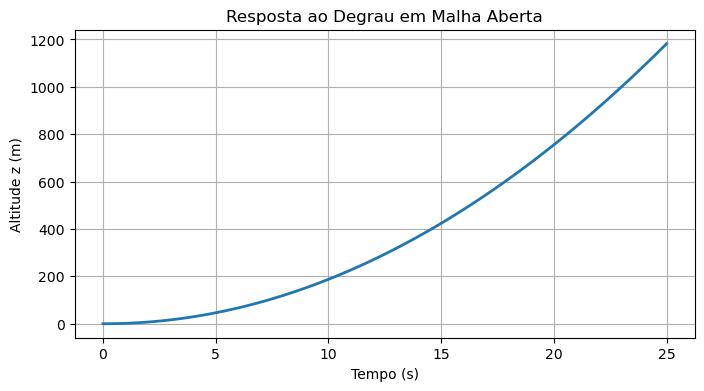

In [4]:
# Obtendo os polos da malha aberta
polos = ct.poles(Gs)
print(f"Polos da Planta em Malha Aberta: {polos}")

# Simulando a resposta ao degrau unitário (malha aberta)
t, y = ct.step_response(Gs)

# Plotagem
plt.figure(figsize=(8, 4))
plt.plot(t, y, linewidth=2)
plt.title('Resposta ao Degrau em Malha Aberta')
plt.xlabel('Tempo (s)')
plt.ylabel('Altitude z (m)')
plt.grid(True)
plt.show()

## 3.1. Análise do Lugar das Raízes (Controlador Proporcional)

Para investigar as características dinâmicas em malha fechada, aplicamos inicialmente um Controlador Proporcional simples $C(s) = K_p$. A análise do Lugar das Raízes (Root Locus) permite visualizar a trajetória dos polos de malha fechada conforme variamos o ganho $K_p$ de $0$ a $\infty$.

Como o sistema possui três polos ($n = 3$) e nenhum zero ($m = 0$), o traçado do Lugar das Raízes possuirá três assíntotas (ângulos de 60°, 180° e -60°). O fenômeno crítico desta planta ocorre devido aos dois polos na origem: assim que qualquer ganho $K_p > 0$ for aplicado, os ramos partindo da origem migram imediatamente para o semiplano direito (ou eixo imaginário puro, dependendo do arranjo), tornando o sistema em malha fechada estruturalmente instável ou eternamente oscilatório.

Isso demonstra teoricamente que **um controle estritamente Proporcional é incapaz de estabilizar a altitude de um quadricóptero**. A introdução de uma ação Derivativa (para adicionar amortecimento) e possivelmente Integral (para zerar o erro de regime) torna-se mandatória.

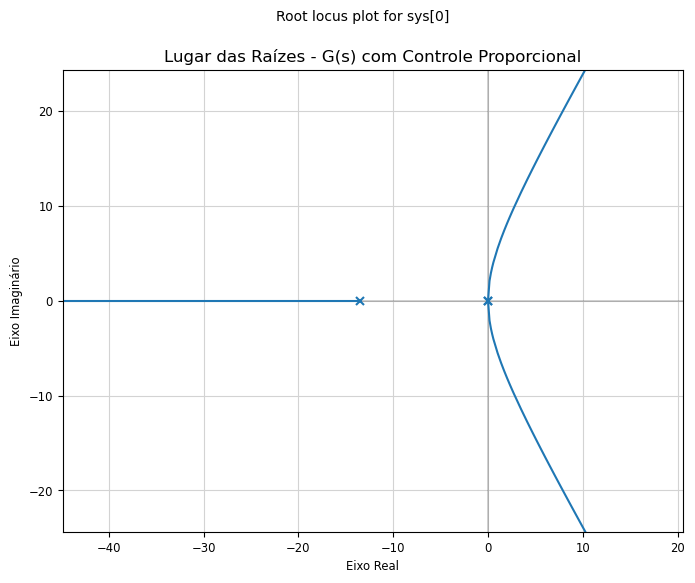

In [8]:
# Traçando o Lugar das Raízes da planta (Comportamento de ganho Proporcional)

warnings.filterwarnings("ignore")
logging.getLogger('matplotlib').setLevel(logging.ERROR)

plt.figure(figsize=(8, 6))

ct.root_locus(Gs, grid=False) 

plt.title('Lugar das Raízes - G(s) com Controle Proporcional')
plt.xlabel('Eixo Real')
plt.ylabel('Eixo Imaginário')
plt.grid(True, color='lightgray', linestyle='-')
plt.show()

# 4. Projeto do Controlador PID

Como demonstrado pela análise do Lugar das Raízes, a estabilização da altitude do quadricóptero requer a adição de zeros ao sistema para atrair os ramos do lugar das raízes para o semiplano esquerdo (estável). Isso é obtido através de um controlador PID, cuja função de transferência possui a forma:

$$C(s) = K_p + \frac{K_i}{s} + K_d s = \frac{K_d s^2 + K_p s + K_i}{s}$$

## 4.1. Requisitos de Desempenho e Polos Desejados

Para garantir um voo estável e viável do ponto de vista do consumo de energia dos motores elétricos, os seguintes requisitos no domínio do tempo foram definidos:

* **Sobressinal Máximo ($UP \le 5\%$):** Limitar o sobressinal a 5% garante que, ao receber um comando de subida, a aeronave não ultrapasse bruscamente a altitude desejada. Em voos próximos a obstáculos, um alto sobressinal resulta em risco de colisão. Além disso, evita-se a exigência de desacelerações bruscas, economizando bateria.
* **Tempo de Acomodação ($t_s \le 2$ segundos para critério de 2%):** A faixa de 2 segundos confere agilidade para que o drone rejeite perturbações externas (como rajadas de vento) em regime linear (pequenos desvios). Tempos menores exigiriam tensões irreais, saturando os motores, enquanto tempos maiores deixariam o voo instável e com resposta excessivamente lenta.

A partir destes requisitos, calcula-se o fator de amortecimento ($\zeta$) e a frequência natural não-amortecida ($\omega_n$) desejados para os polos dominantes de malha fechada.

**1. Fator de Amortecimento ($\zeta$):**
$$UP = e^{\frac{-\zeta \pi}{\sqrt{1-\zeta^2}}} \implies 0.05 = e^{\frac{-\zeta \pi}{\sqrt{1-\zeta^2}}} \implies \zeta \approx 0.69$$

**2. Frequência Natural ($\omega_n$):**
Utilizando a aproximação clássica para o tempo de acomodação (critério de 2%):
$$t_s = \frac{4}{\zeta \omega_n} \implies 2 = \frac{4}{0.69 \cdot \omega_n} \implies \omega_n \approx 2.89 \text{ rad/s}$$

**3. Polos Dominantes Desejados ($s_d$):**
A localização ideal dos polos no plano $s$ que atende à dinâmica estipulada é dada por:
$$s_d = -\zeta \omega_n \pm j \omega_n \sqrt{1 - \zeta^2}$$
$$s_d = -(0.69)(2.89) \pm j (2.89) \sqrt{1 - 0.69^2}$$
$$s_d = -2.00 \pm j 2.10$$

Portanto, o projeto do controlador PID consiste em sintonizar os ganhos para forçar as raízes da equação característica de malha fechada a passarem exatamente pelo ponto $s_d = -2.00 + j 2.10$.